# Ejemplo 3 – Red neuronal para series de tiempo (clasificación de series)
**Problema industrial:** detectar si un motor automotriz tiene una falla a partir de la serie de
tiempo de 500 muestras de su sensor de ruido/vibración (diagnóstico de fin de línea, Ford).

**Dataset:** *FordA* – UCR/UEA Time Series Classification Archive (WCCI 2008 Ford Classification
Challenge). 3 601 series de entrenamiento y 1 320 de prueba, longitud 500, 2 clases.
https://www.timeseriesclassification.com/description.php?Dataset=FordA

**Red:** red convolucional 1D (FCN, Wang et al. 2017) con 3 bloques Conv1D + BatchNorm + ReLU,
Global Average Pooling y salida softmax, Keras/TensorFlow.

Alumno: Alessandro Díaz – Sistemas Inteligentes, UAC.

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alessdi/PracticaMachineLearning/blob/main/notebooks/03_series_tiempo_forda.ipynb)

Ejecutar con **Entorno de ejecución → Ejecutar todas**. Los datos se descargan automáticamente.

In [1]:
import os, sys, time
import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
RESULTADOS = "../resultados" if os.path.isdir("../data") else "resultados"
os.makedirs(RESULTADOS, exist_ok=True)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Carga del dataset

Entrenamiento: (3601, 500, 1)  Prueba: (1320, 500, 1)
Balance de clases (entrenamiento): [1846 1755]


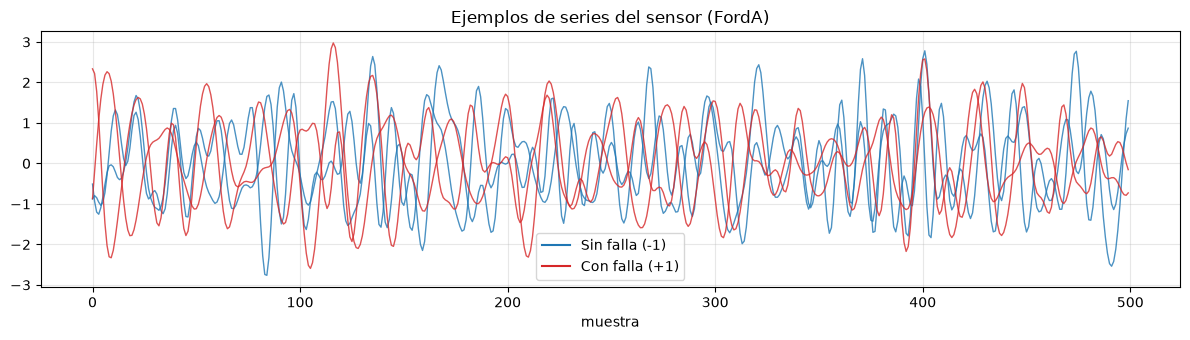

In [2]:
URL_UCR = "https://raw.githubusercontent.com/hfawaz/cd-diagram/master/FordA/"
URL_REPO = "https://raw.githubusercontent.com/alessdi/PracticaMachineLearning/main/data/"

def cargar_forda(nombre):
    for ruta in (f"data/{nombre}", f"../data/{nombre}"):
        if os.path.exists(ruta):
            datos = np.loadtxt(ruta, delimiter="\t"); break
    else:
        try:
            datos = np.loadtxt(URL_UCR + nombre, delimiter="\t")
        except Exception as e:
            print("Fuente UCR no disponible:", e)
            datos = np.loadtxt(URL_REPO + nombre, delimiter="\t")
    y = (datos[:, 0] == 1).astype(int)          # -1 -> 0 (sin falla), 1 -> 1 (con falla)
    x = datos[:, 1:].astype("float32")[..., np.newaxis]
    return x, y

x_ent_total, y_ent_total = cargar_forda("FordA_TRAIN.tsv")
x_pru, y_pru = cargar_forda("FordA_TEST.tsv")
CLASES = ["Sin falla (-1)", "Con falla (+1)"]
print("Entrenamiento:", x_ent_total.shape, " Prueba:", x_pru.shape)
print("Balance de clases (entrenamiento):", np.bincount(y_ent_total))

# 15 % del conjunto de entrenamiento se reserva para validación (parada temprana y ajuste)
x_ent, x_val, y_ent, y_val = train_test_split(x_ent_total, y_ent_total, test_size=0.15,
                                              stratify=y_ent_total, random_state=SEMILLA)

fig, ax = plt.subplots(figsize=(12, 3.5))
for c, color in zip([0, 1], ["tab:blue", "tab:red"]):
    for serie in x_ent[y_ent == c][:2]:
        ax.plot(serie.ravel(), color=color, alpha=.8, lw=1)
    ax.plot([], color=color, label=CLASES[c])
ax.set_title("Ejemplos de series del sensor (FordA)"); ax.set_xlabel("muestra"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(f"{RESULTADOS}/series_ejemplos.png", dpi=130); plt.show()

## 2. Modelo convolucional 1D y ajuste de parámetros

In [3]:
def crear_modelo(filtros, kernel, tasa):
    entrada = keras.Input(shape=x_ent.shape[1:])
    h = entrada
    for _ in range(3):
        h = keras.layers.Conv1D(filtros, kernel, padding="same")(h)
        h = keras.layers.BatchNormalization()(h)
        h = keras.layers.ReLU()(h)
    h = keras.layers.GlobalAveragePooling1D()(h)
    salida = keras.layers.Dense(2, activation="softmax")(h)
    modelo = keras.Model(entrada, salida)
    modelo.compile(optimizer=keras.optimizers.Adam(tasa),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo

def entrenar(filtros, kernel, tasa, epocas, verbose=0):
    keras.utils.set_random_seed(SEMILLA)
    modelo = crear_modelo(filtros, kernel, tasa)
    cb = [keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-4),
          keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)]
    hist = modelo.fit(x_ent, y_ent, validation_data=(x_val, y_val), epochs=epocas,
                      batch_size=32, callbacks=cb, verbose=verbose)
    return modelo, hist

# Búsqueda corta (30 épocas) de número de filtros y tamaño de kernel
REJILLA = [(32, 3, 1e-3), (64, 3, 1e-3), (64, 7, 1e-3)]
resultados = []
for filtros, kernel, tasa in REJILLA:
    t0 = time.time()
    modelo, hist = entrenar(filtros, kernel, tasa, epocas=30)
    acc_val = modelo.evaluate(x_val, y_val, verbose=0)[1]
    resultados.append({"filtros": filtros, "kernel": kernel, "tasa": tasa,
                       "exactitud val %": round(100 * acc_val, 2), "tiempo s": round(time.time() - t0, 1)})
    print(resultados[-1])
tabla_ajuste = pd.DataFrame(resultados)
tabla_ajuste.to_csv(f"{RESULTADOS}/series_ajuste.csv", index=False)
print(tabla_ajuste.to_string(index=False))

{'filtros': 32, 'kernel': 3, 'tasa': 0.001, 'exactitud val %': 87.06, 'tiempo s': 26.7}


{'filtros': 64, 'kernel': 3, 'tasa': 0.001, 'exactitud val %': 87.8, 'tiempo s': 61.0}


{'filtros': 64, 'kernel': 7, 'tasa': 0.001, 'exactitud val %': 92.61, 'tiempo s': 95.9}
 filtros  kernel  tasa  exactitud val %  tiempo s
      32       3 0.001            87.06      26.7
      64       3 0.001            87.80      61.0
      64       7 0.001            92.61      95.9


## 3. Entrenamiento final con la mejor configuración

In [4]:
mejor = tabla_ajuste.loc[tabla_ajuste["exactitud val %"].idxmax()]
print(f"Mejor configuración: filtros={int(mejor['filtros'])}, kernel={int(mejor['kernel'])}, tasa={mejor['tasa']}")
modelo, hist = entrenar(int(mejor["filtros"]), int(mejor["kernel"]), float(mejor["tasa"]), epocas=150, verbose=2)
modelo.summary()
modelo.save(f"{RESULTADOS}/modelo_forda.keras")

Mejor configuración: filtros=64, kernel=7, tasa=0.001
Epoch 1/150


96/96 - 4s - 40ms/step - accuracy: 0.8131 - loss: 0.3940 - val_accuracy: 0.4880 - val_loss: 0.7765 - learning_rate: 0.0010


Epoch 2/150


96/96 - 3s - 36ms/step - accuracy: 0.8775 - loss: 0.2922 - val_accuracy: 0.4880 - val_loss: 0.9164 - learning_rate: 0.0010


Epoch 3/150


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 500, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 500, 64)        │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 500, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 500, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_10 (Conv1D)              │ (None, 500, 64)        │        28,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 500, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_10 (ReLU)                 │ (None, 500, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_11 (Conv1D)              │ (None, 500, 64)        │        28,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 500, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_11 (ReLU)                 │ (None, 500, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_3      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,880 (687.04 KB)

 Trainable params: 58,498 (228.51 KB)

 Non-trainable params: 384 (1.50 KB)

 Optimizer params: 116,998 (457.03 KB)

## 4. Evaluación en el conjunto de prueba oficial (1 320 series nunca vistas)

Exactitud  entrenamiento: 95.13 %  validación: 93.90 %  prueba: 93.79 %
                precision    recall  f1-score   support

Sin falla (-1)      0.942     0.937     0.940       681
Con falla (+1)      0.933     0.939     0.936       639

      accuracy                          0.938      1320
     macro avg      0.938     0.938     0.938      1320
  weighted avg      0.938     0.938     0.938      1320



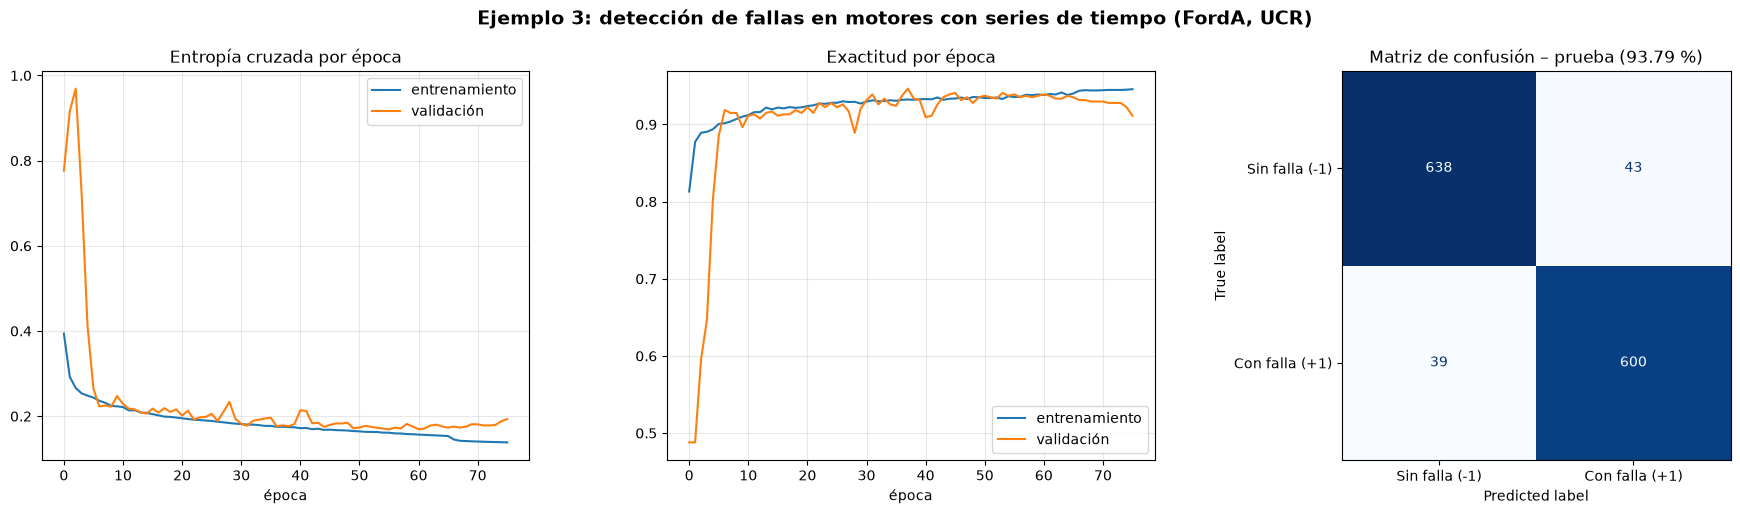

In [5]:
prob = modelo.predict(x_pru, verbose=0)
y_pred = prob.argmax(axis=1)
acc_ent = accuracy_score(y_ent, modelo.predict(x_ent, verbose=0).argmax(axis=1))
acc_val = accuracy_score(y_val, modelo.predict(x_val, verbose=0).argmax(axis=1))
acc_pru = accuracy_score(y_pru, y_pred)
print(f"Exactitud  entrenamiento: {100*acc_ent:.2f} %  validación: {100*acc_val:.2f} %  prueba: {100*acc_pru:.2f} %")
print(classification_report(y_pru, y_pred, target_names=CLASES, digits=3))

fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
ax[0].plot(hist.history["loss"], label="entrenamiento"); ax[0].plot(hist.history["val_loss"], label="validación")
ax[0].set_title("Entropía cruzada por época"); ax[0].set_xlabel("época"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(hist.history["accuracy"], label="entrenamiento"); ax[1].plot(hist.history["val_accuracy"], label="validación")
ax[1].set_title("Exactitud por época"); ax[1].set_xlabel("época"); ax[1].legend(); ax[1].grid(alpha=.3)
ConfusionMatrixDisplay(confusion_matrix(y_pru, y_pred), display_labels=CLASES).plot(ax=ax[2], cmap="Blues", colorbar=False)
ax[2].set_title(f"Matriz de confusión – prueba ({100*acc_pru:.2f} %)")
fig.suptitle("Ejemplo 3: detección de fallas en motores con series de tiempo (FordA, UCR)", fontsize=14, weight="bold")
fig.tight_layout(); fig.savefig(f"{RESULTADOS}/series_forda.png", dpi=130); plt.show()

## 5. Uso del modelo: diagnosticar series nuevas

In [6]:
def diagnosticar_motor(serie):
    """serie: arreglo de 500 lecturas normalizadas del sensor."""
    p = modelo.predict(np.asarray(serie, dtype="float32").reshape(1, -1, 1), verbose=0)[0]
    return CLASES[p.argmax()], p.max()

rng = np.random.default_rng(3)
for i in rng.choice(len(x_pru), 6, replace=False):
    clase, p = diagnosticar_motor(x_pru[i])
    print(f"Serie de prueba {i:4d}: real = {CLASES[y_pru[i]]:15s} -> red = {clase:15s} (p = {p:.3f})")

Serie de prueba  112: real = Sin falla (-1)  -> red = Con falla (+1)  (p = 0.630)
Serie de prueba  239: real = Con falla (+1)  -> red = Con falla (+1)  (p = 0.997)
Serie de prueba  312: real = Sin falla (-1)  -> red = Con falla (+1)  (p = 1.000)
Serie de prueba 1067: real = Con falla (+1)  -> red = Con falla (+1)  (p = 0.953)
Serie de prueba  236: real = Con falla (+1)  -> red = Con falla (+1)  (p = 0.995)
Serie de prueba 1057: real = Con falla (+1)  -> red = Con falla (+1)  (p = 0.999)
